In [1]:
import sys
from pathlib import Path
import logging
from pathlib import Path
from typing import Any, Dict, List, Optional

# 1. Point to the 'backend' folder (the parent of 'src')
backend_path = Path.cwd().resolve()
while backend_path.name != "backend" and backend_path.parent != backend_path:
    backend_path = backend_path.parent

if str(backend_path) not in sys.path:
    sys.path.insert(0, str(backend_path))

print("Added to sys.path:", backend_path)

# 2. Always import with the 'src.' prefix so package hierarchies match
from src.config import DATA_DIR, logger
from src.ingestion import (
    CanonicalRecord,
    execute_incremental_ingestion_batch,
    process_file_with_validation,
)
from src.schema import SCHEMA_CONFIG
from src.agent.state import WikiState
from src.agent.nodes.collect_data import collect_data
import operator
from typing import Annotated, Any, Dict, List, Optional, TypedDict


Added to sys.path: C:\Users\ps302\OneDrive\Desktop\garph hacks\backend


In [ ]:
# import os
# from IPython.display import display, Markdown
# # Model specify kar sakte hain (default already 'gpt-oss:120b-cloud' hai):
# os.environ["OLLAMA_MODEL"] = "gpt-oss:120b-cloud"

# from src.query_agent import ask_company_brain

# query = "Tell me about DEPT-ENG, who heads it, and what teams belong to it?"
# result = ask_company_brain(query)

# print("=" * 60)
# print("OLLAMA SYNTHESIZED ANSWER:")
# print("=" * 60)
# display(Markdown(result["final_answer"]))

# print("\n" + "=" * 60)
# print(" EVIDENCE & CITATIONS:")
# print("=" * 60)
# for citation in result.get("evidence_citations", []):
#     print(f"- {citation}")


2026-10-17 01:27:59,831 [INFO] company_brain: --- [Query Agent Node 1] parse_user_intent: 'Tell me about DEPT-ENG, who heads it, and what teams belong to it?' ---
2026-10-17 01:27:59,832 [INFO] company_brain: Identified starting entities: ['DEPT-ENG']
2026-10-17 01:27:59,834 [INFO] company_brain: --- [Query Agent Node 2] traverse_graph from ['DEPT-ENG'] ---
2026-10-17 01:27:59,835 [INFO] company_brain: Graph Traversal found 2 nodes and 2 edges.
2026-10-17 01:27:59,837 [INFO] company_brain: --- [Query Agent Node 3] read_wiki_pages for 2 nodes ---
2026-10-17 01:27:59,839 [INFO] company_brain: Successfully loaded 2 living Wiki pages into context.
2026-10-17 01:27:59,840 [INFO] company_brain: --- [Query Agent Node 4] synthesize_answer for 'Tell me about DEPT-ENG, who heads it, and what teams belong to it?' ---
2026-10-17 01:28:02,218 [INFO] company_brain: Successfully generated answer using Ollama model [gpt-oss:120b-cloud]


OLLAMA SYNTHESIZED ANSWER:


**Department Overview – Engineering (`DEPT-ENG`)**

| Property | Value |
|---|---|
| **Display name** | Engineering |
| **Department ID** | `DEPT-ENG` |
| **Mission** | “Build and operate reliable product software” |
| **Created at** | 2025‑01‑01 09:00 UTC |
| **Head (lead) employee** | `EMP-0001` – the employee who LED_BY the department【departments\DEPT-ENG.md】 |

### Who heads DEPT‑ENG?
The Engineering department is led by **Employee EMP‑0001**. This is shown by the outgoing **LED_BY** relationship from `DEPT-ENG` to `EMP-0001` in the graph, and the department’s `head_employee_id` field also lists `EMP-0001`【departments\DEPT-ENG.md】. The employee record confirms the incoming **LED_BY** link from the department【employees\EMP-0001.md】.

### Teams belonging to DEPT‑ENG
The current knowledge base (both the graph relationships and the living‑wiki pages) does **not contain any team entities linked to `DEPT-ENG`**. No “HAS_TEAM”, “INCLUDES”, or similar relationships are recorded, and the department page lists only the head employee. If teams exist in the organization, they have not yet been synced into the wiki or graph store.

---

**Key sources**

- Department page: `departments\DEPT-ENG.md` (core properties, LED_BY relation)  
- Employee page: `employees\EMP-0001.md` (incoming LED_BY relation)  

If you need details on specific teams, let me know and I can check whether they are recorded under a different identifier or help you add that information to the system.


 EVIDENCE & CITATIONS:
- departments\DEPT-ENG.md
- employees\EMP-0001.md


In [5]:

def merge_canonical_records(
    left: Optional[Dict[str, List[Dict[str, Any]]]], 
    right: Optional[Dict[str, List[Dict[str, Any]]]]
) -> Dict[str, List[Dict[str, Any]]]:
    """
    Reducer that merges canonical records grouped by entity_type,
    deduplicating/updating by entity_id.
    """
    if not left:
        return dict(right or {})
    if not right:
        return dict(left)

    result = {k: list(v) for k, v in left.items()}
    for entity_type, new_records in right.items():
        if entity_type not in result:
            result[entity_type] = list(new_records)
        else:
            existing_map = {rec["entity_id"]: idx for idx, rec in enumerate(result[entity_type])}
            for rec in new_records:
                eid = rec.get("entity_id")
                if eid in existing_map:
                    result[entity_type][existing_map[eid]] = rec
                else:
                    result[entity_type].append(rec)
                    existing_map[eid] = len(result[entity_type]) - 1
    return result


def merge_dicts(
    left: Optional[Dict[str, Any]], 
    right: Optional[Dict[str, Any]]
) -> Dict[str, Any]:
    """Reducer that merges dictionary keys safely during parallel execution."""
    merged = dict(left or {})
    if right:
        merged.update(right)
    return merged


def take_latest(left: Any, right: Any) -> Any:
    """Reducer that accepts the latest updated value."""
    return right if right is not None else left


class WikiState(TypedDict, total=False):
    """
    Complete state passed between nodes in the Company Brain LangGraph pipeline.
    All list and dict fields used in parallel branches have reducer annotations.
    """
    # Ingestion Configuration
    reset_manifest: Optional[bool]
    batch_id: Annotated[str, take_latest]
    chunk_size: int
    data_dir: Optional[str]
    max_workers: int
    files_to_process: List[str]

    # Change Detection & Incremental Watermarks
    previous_hashes: Dict[str, str]
    current_hashes: Annotated[Dict[str, str], merge_dicts]
    changed_entities: Dict[str, List[str]]  # {"added": [...], "updated": [...], "unchanged": [...]}
    quarantined_records: Annotated[List[Dict[str, Any]], operator.add]
    
    # Foreign Key Resolution Queues
    unresolved_foreign_keys: Annotated[Dict[str, Any], merge_dicts]
    now_resolved_foreign_keys: Annotated[Dict[str, Any], merge_dicts]

    # Ingested Canonical Records and Edges
    canonical_records: Annotated[Dict[str, List[Dict[str, Any]]], merge_canonical_records]
    relationships_records: Annotated[List[Dict[str, Any]], operator.add]

    # Dirty Entity IDs for Incremental Wiki Generation
    dirty_entity_ids: Annotated[List[str], take_latest]

    # Audit & Status
    audit_report: Annotated[Dict[str, Any], merge_dicts]
    branch_status: Annotated[Dict[str, str], merge_dicts]

    # Observability & Chunk Metadata
    chunk_metadata: Annotated[List[Dict[str, Any]], operator.add]
    stats: Annotated[Dict[str, Any], merge_dicts]
    errors: Annotated[List[str], operator.add]

    # Retrieval Interface
    query_text: Optional[str]
    target_entity_id: Optional[str]
    query_result: Annotated[Dict[str, Any], merge_dicts]

    # Pipeline Stage Tracking
    stage: Annotated[str, take_latest]


In [6]:
def create_initial_wiki_state(
    chunk_size: int = 500,
    files_to_process: Optional[List[str]] = None,
    previous_hashes: Optional[Dict[str, str]] = None,
    max_workers: int = 4,
    data_dir: Optional[str] = None,
    batch_id: Optional[str] = None,
    reset_manifest: bool = False,
    query_text: Optional[str] = None,
    target_entity_id: Optional[str] = None,
) -> WikiState:
    """Helper to initialize an empty WikiState with defaults."""
    return {
        "reset_manifest": reset_manifest,
        "batch_id": batch_id or "",
        "chunk_size": chunk_size,
        "data_dir": data_dir,
        "max_workers": max_workers,
        "files_to_process": files_to_process or [],
        "previous_hashes": previous_hashes or {},
        "current_hashes": {},
        "changed_entities": {"added": [], "updated": [], "unchanged": []},
        "quarantined_records": [],
        "unresolved_foreign_keys": {},
        "now_resolved_foreign_keys": {},
        "canonical_records": {},
        "relationships_records": [],
        "dirty_entity_ids": [],
        "audit_report": {},
        "branch_status": {},
        "chunk_metadata": [],
        "stats": {},
        "errors": [],
        "query_text": query_text,
        "target_entity_id": target_entity_id,
        "query_result": {},
        "stage": "initialized",
    }


In [7]:
def collect_data(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node: Collect and parse company data in chunks across files with Step 1 validation.

    Performs:
    1. Checkpoint & batch ID initialization.
    2. In-chunk conflict & duplicate quarantine.
    3. Delta classification: added, updated (with field diffs), unchanged.
    4. Detection of missing parents / unresolved foreign-keys.
    5. Storage into WikiState for downstream graph synchronization.
    """
    logger.info("--- [LangGraph Node: collect_data] Executing Step 1 Ingestion Pipeline ---")

    chunk_size = state.get("chunk_size", 500)
    max_workers = state.get("max_workers", 4)
    data_dir_str = state.get("data_dir")
    data_dir = Path(data_dir_str) if data_dir_str else DATA_DIR
    batch_id = state.get("batch_id")

    # Dynamically determine files to process
    files_to_process = state.get("files_to_process")
    if not files_to_process:
        files_to_process = list(SCHEMA_CONFIG.keys())
        if (data_dir / "relationships.csv").exists():
            files_to_process.append("relationships.csv")

    logger.info(f"Ingesting {len(files_to_process)} CSV files with chunk_size={chunk_size}, workers={max_workers}")

    previous_hashes = state.get("previous_hashes")
    reset_manifest = state.get("reset_manifest", False)

    # Run the Step 1 validated batch ingestion engine
    batch_result = execute_incremental_ingestion_batch(
        filenames=files_to_process,
        data_dir=data_dir,
        chunk_size=chunk_size,
        batch_id=batch_id,
        previous_hashes=previous_hashes,
        max_workers=max_workers,
        persist_manifest=True,
        reset_manifest=reset_manifest,
    )

    records_by_type = batch_result["records_by_type"]
    relationships = batch_result["relationships"]
    all_hashes = batch_result["current_hashes"]
    quarantined = batch_result["quarantined"]
    unresolved_fks = batch_result["unresolved_foreign_keys"]
    now_resolved_fks = batch_result["now_resolved_foreign_keys"]
    chunk_meta = batch_result["chunk_metadata"]
    errors = batch_result["errors"]
    stats = batch_result["stats"]

    # Compute categorized list of changed entity IDs
    added_ids: List[str] = []
    updated_ids: List[str] = []
    unchanged_ids: List[str] = []

    for label, records in records_by_type.items():
        for rec in records:
            eid = rec["entity_id"]
            ctype = rec.get("change_type", "added")
            if ctype == "added":
                added_ids.append(eid)
            elif ctype == "updated":
                updated_ids.append(eid)
            else:
                unchanged_ids.append(eid)

    changed_summary = {
        "added": added_ids,
        "updated": updated_ids,
        "unchanged": unchanged_ids,
    }

    logger.info(
        f"Data collection complete [Batch {batch_result['batch_id']}]: "
        f"{stats['total_canonical_entities']} entities, {stats['total_relationships']} edges. "
        f"(Added: {len(added_ids)}, Updated: {len(updated_ids)}, Unchanged: {len(unchanged_ids)}, "
        f"Quarantined: {len(quarantined)}, Unresolved FKs: {len(unresolved_fks)})"
    )

    # Return partial state update for LangGraph reducers
    return {
        "batch_id": batch_result["batch_id"],
        "canonical_records": records_by_type,
        "relationships_records": relationships,
        "current_hashes": all_hashes,
        "changed_entities": changed_summary,
        "quarantined_records": quarantined,
        "unresolved_foreign_keys": unresolved_fks,
        "now_resolved_foreign_keys": now_resolved_fks,
        "chunk_metadata": chunk_meta,
        "stats": stats,
        "errors": errors,
        "stage": "data_collected",
    }


In [8]:
# from src.agent.nodes.collect_data import collect_data
# from src.agent.state import create_initial_wiki_state

# # Initial khali state
# state = create_initial_wiki_state(files_to_process=["departments.csv"])
# print("Before collect_data:", state["canonical_records"]) # Output: {}

# # Node execute hua
# update = collect_data(state)

# print("Keys returned by collect_data:", list(update.keys()))
# print("Total Departments in returned state:", len(update["canonical_records"]["Department"]))


In [9]:
# out = collect_data(state)

In [10]:
"""
sync_graph.py — LangGraph node for Step 2 FalkorDB Synchronization & Edge Reconciliation.
Processes canonical records and relationships from state, reconciles edges, and manages placeholders.
"""
from typing import Any, Dict, List
from src.config import logger
from src.graph_store import GraphStore
# from src.state import WikiState
from src.schema import FK_TO_RELATIONSHIP


# Shared graph store singleton across pipeline runs
_GRAPH_STORE_INSTANCE: GraphStore = None


def get_graph_store() -> GraphStore:
    """Retrieve or initialize the active GraphStore instance."""
    global _GRAPH_STORE_INSTANCE
    if _GRAPH_STORE_INSTANCE is None:
        _GRAPH_STORE_INSTANCE = GraphStore()
        _GRAPH_STORE_INSTANCE.connect()
    return _GRAPH_STORE_INSTANCE


def sync_falkordb_graph(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node (Step 2):
    1. Ingests canonical entities into FalkorDB/GraphStore idempotently.
    2. Upserts foreign-key relationships and reconciles stale edges.
    3. Ingests explicit relationships from relationships.csv.
    4. Tracks resolved placeholder parent nodes.
    """
    logger.info("--- [LangGraph Node: sync_falkordb_graph] Executing Step 2 Graph Synchronization ---")

    store = get_graph_store()
    canonical_records = state.get("canonical_records", {})
    relationships_records = state.get("relationships_records", [])

    total_entities_upserted = 0
    reconciled_edges_count = 0
    stale_edges_closed = []

    # 1. Upsert Canonical Entities
    for label, records in canonical_records.items():
        res = store.upsert_entities_batch(records)
        total_entities_upserted += len(records)

    # 2. Reconcile Foreign Key Relationships
    for label, records in canonical_records.items():
        for rec in records:
            src_id = rec["entity_id"]
            src_type = rec["entity_type"]
            fks = rec.get("foreign_keys", {})

            for fk_col, fk_info in fks.items():
                if isinstance(fk_info, (list, tuple)) and len(fk_info) == 3:
                    target_type, target_pk, target_val = fk_info[0], fk_info[1], fk_info[2]
                    rel_type = FK_TO_RELATIONSHIP.get(fk_col, "RELATED_TO")

                    recon_res = store.reconcile_relationship(
                        source_id=src_id,
                        source_type=src_type,
                        relationship_type=rel_type,
                        new_target_id=target_val,
                        target_type=target_type,
                    )
                    reconciled_edges_count += 1
                    if recon_res.get("stale_targets_closed"):
                        stale_edges_closed.extend(recon_res["stale_targets_closed"])

    # 3. Upsert Explicit Relationships (from relationships.csv)
    for rel in relationships_records:
        recon_res = store.reconcile_relationship(
            source_id=rel["source_id"],
            source_type=rel["source_type"],
            relationship_type=rel["relationship_type"],
            new_target_id=rel["target_id"],
            target_type=rel["target_type"],
            evidence_text=rel.get("evidence_text"),
            valid_from=rel.get("valid_from"),
        )
        reconciled_edges_count += 1

    graph_stats = store.get_stats()
    logger.info(
        f"Graph Sync Complete: {graph_stats['total_nodes']} total nodes ({graph_stats['placeholder_nodes']} placeholders), "
        f"{graph_stats['total_relationships']} active edges. (Closed {len(stale_edges_closed)} stale edges)."
    )

    return {
        "branch_status": {"falkordb": "SYNCED"},
        "stage": "graph_synced",
        "stats": {
            **state.get("stats", {}),
            "graph_nodes": graph_stats["total_nodes"],
            "graph_edges": graph_stats["total_relationships"],
            "placeholder_nodes": graph_stats["placeholder_nodes"],
            "stale_edges_closed": len(stale_edges_closed),
        }
    }


In [11]:
"""
detect_dirty.py — LangGraph node for Step 3 Dependency-Aware Dirty-Page Detection.
Identifies precisely which Wiki pages must be created or refreshed based on:
1. Newly added or updated entities.
2. Modified relationships (both source and target endpoints).
3. 1-hop graph dependency neighborhood rules.
"""
from typing import Any, Dict, List, Set


def get_dynamic_dependency_rules() -> Dict[str, Set[str]]:
    """
    Dynamically generates the dirty dependency rules by inverting foreign keys
    defined in SCHEMA_CONFIG.
    
    If entity X points to entity Y via foreign key (e.g. Team -> Department),
    then when X changes or is added, Y is affected and marked dirty.
    Also handles bidirectional relationships (e.g. Employee <-> Team).
    """
    rules: Dict[str, Set[str]] = {}

    for file_name, config in SCHEMA_CONFIG.items():
        source_label = config.get("label")
        if not source_label:
            continue

        if source_label not in rules:
            rules[source_label] = set()

        fk_map = config.get("fk", {})
        for fk_col, target_spec in fk_map.items():
            if isinstance(target_spec, (list, tuple)) and len(target_spec) >= 1:
                target_label = target_spec[0]
                # If source points to target, target is an impacted parent/dependency
                rules[source_label].add(target_label)

    return rules


def detect_dirty_entities(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node (Step 3):
    Computes a deduplicated set of dirty entity IDs that need Wiki page generation/regeneration:
    - Added entities (need new pages)
    - Updated entities (need refreshed pages)
    - 1-hop graph neighbors dynamically derived from SCHEMA_CONFIG
    """
    logger.info("--- [LangGraph Node: detect_dirty_entities] Executing Step 3 Dirty Detection ---")

    store = get_graph_store()
    changed_entities = state.get("changed_entities", {})
    added_ids = set(changed_entities.get("added", []))
    updated_ids = set(changed_entities.get("updated", []))

    dirty_set: Set[str] = set()

    # 1. Direct dirty entities (added + updated)
    dirty_set.update(added_ids)
    dirty_set.update(updated_ids)

    # 2. Dynamic Dependency Rules from SCHEMA_CONFIG
    dependency_rules = get_dynamic_dependency_rules()
    impacted_neighbors: Set[str] = set()

    for eid in (added_ids | updated_ids):
        node = store.in_memory_nodes.get(eid)
        if not node:
            continue
        entity_label = node.get("label", "")
        allowed_neighbor_labels = dependency_rules.get(entity_label, set())

        if not allowed_neighbor_labels:
            continue

        neighbors = store.get_neighbors(eid, direction="both")
        for nb in neighbors:
            nb_label = nb.get("neighbor_label")
            nb_id = nb.get("neighbor_id")
            if nb_label in allowed_neighbor_labels and nb_id:
                impacted_neighbors.add(nb_id)

    # 3. Add impacted neighbors to the dirty set
    dirty_set.update(impacted_neighbors)

    logger.info(
        f"Dirty Detection Complete: {len(dirty_set)} total dirty entities "
        f"({len(added_ids)} added, {len(updated_ids)} updated, {len(impacted_neighbors)} impacted neighbors)."
    )

    return {
        "dirty_entity_ids": list(dirty_set),
        "stage": "dirty_entities_detected",
        "stats": {
            **state.get("stats", {}),
            "total_dirty_pages": len(dirty_set),
            "impacted_neighbor_pages": len(impacted_neighbors),
        }
    }


In [12]:
"""
sync_wiki.py — LangGraph node for Step 4 Living Wiki Generation.
Renders deterministic Markdown files for dirty entities with graph hydration and manual notes protection.
"""
from typing import Any, Dict, List

from src.wiki_builder import WikiBuilder



def sync_llm_wiki(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node (Step 4):
    Builds or updates living Wiki pages for all detected dirty entities.
    """
    logger.info("--- [LangGraph Node: sync_llm_wiki] Executing Step 4 Wiki Generation ---")

    store = get_graph_store()
    builder = WikiBuilder(graph_store=store)
    dirty_entity_ids = state.get("dirty_entity_ids", [])
    canonical_records = state.get("canonical_records", {})

    # If dirty_entity_ids is empty, default to rendering all canonical records in state
    if not dirty_entity_ids:
        all_eids = []
        for recs in canonical_records.values():
            all_eids.extend([r["entity_id"] for r in recs])
        dirty_entity_ids = all_eids

    wiki_res = builder.sync_dirty_pages(
        dirty_entity_ids=dirty_entity_ids,
        canonical_records=canonical_records,
    )

    logger.info(f"Living Wiki Sync Complete: {wiki_res['total_rendered']} pages generated/updated in {wiki_res['wiki_directory']}")

    return {
        "branch_status": {"wiki": "SYNCED"},
        "stage": "wiki_synced",
        "stats": {
            **state.get("stats", {}),
            "wiki_pages_rendered": wiki_res["total_rendered"],
        }
    }


In [13]:
"""
audit_node.py — LangGraph node for Step 5 Consistency Audit.
Runs entity, property, and link integrity checks and attaches report to state.
"""
from typing import Any, Dict
from src.audit import ConsistencyAuditor



def audit_consistency(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node (Step 5):
    Verifies parity across CSV sources, FalkorDB graph, and Wiki markdown pages.
    """
    logger.info("--- [LangGraph Node: audit_consistency] Executing Step 5 Consistency Audit ---")

    store = get_graph_store()
    auditor = ConsistencyAuditor(graph_store=store)

    canonical_records = state.get("canonical_records", {})
    quarantined = state.get("quarantined_records", [])

    report = auditor.run_full_audit(
        canonical_records=canonical_records,
        quarantined_records=quarantined,
    )

    logger.info(
        f"Audit Complete: Status = [{report['overall_status']}]. "
        f"Discrepancies: {len(report['discrepancies'])}, Broken Links: {report['link_audit']['broken_links_count']}"
    )

    return {
        "audit_report": report,
        "stage": "completed",
        "stats": {
            **state.get("stats", {}),
            "audit_status": report["overall_status"],
            "broken_wiki_links": report["link_audit"]["broken_links_count"],
        }
    }


In [14]:
"""
retrieve_node.py — LangGraph node for Step 6/7 Grounded Retrieval Interface.
Allows the LangGraph pipeline to execute graph traversal + wiki hydration queries.
"""
from typing import Any, Dict

from src.retrieval import GroundedRetriever


def query_knowledge_base(state: WikiState) -> Dict[str, Any]:
    """
    LangGraph Node (Retrieval Interface):
    If `query_text` is present in state, executes Grounded Retrieval:
    - Finds root entity in graph
    - Performs multi-hop traversal
    - Hydrates context from Living Wiki markdown pages
    - Produces query_result with citations & evidence paths
    """
    query_text = state.get("query_text")
    if not query_text:
        return {"stage": "ready"}

    logger.info(f"--- [LangGraph Node: query_knowledge_base] Query: '{query_text}' ---")

    store = get_graph_store()
    retriever = GroundedRetriever(graph_store=store)

    target_id = state.get("target_entity_id")
    result = retriever.execute_grounded_query(
        query_text=query_text,
        target_entity_id=target_id,
        max_hops=2,
    )

    return {
        "query_result": result,
        "stage": "query_answered",
    }


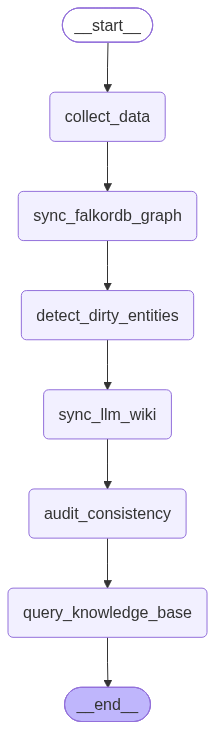

In [15]:
from typing import Any, Dict
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(WikiState)

# ── Nodes ────────────────────────────────────────────────────────────
graph_builder.add_node("collect_data", collect_data)
graph_builder.add_node("sync_falkordb_graph", sync_falkordb_graph)
graph_builder.add_node("detect_dirty_entities", detect_dirty_entities)
graph_builder.add_node("sync_llm_wiki", sync_llm_wiki)
graph_builder.add_node("audit_consistency", audit_consistency)
graph_builder.add_node("query_knowledge_base", query_knowledge_base)

# ── Sequential Graph-First Pipeline Topology ─────────────────────────
graph_builder.add_edge(START, "collect_data")
graph_builder.add_edge("collect_data", "sync_falkordb_graph")
graph_builder.add_edge("sync_falkordb_graph", "detect_dirty_entities")
graph_builder.add_edge("detect_dirty_entities", "sync_llm_wiki")
graph_builder.add_edge("sync_llm_wiki", "audit_consistency")
graph_builder.add_edge("audit_consistency", "query_knowledge_base")
graph_builder.add_edge("query_knowledge_base", END)

workflow = graph_builder.compile()
workflow


In [16]:
state = create_initial_wiki_state(
    files_to_process=["departments.csv","teams.csv" ]    #"teams.csv", "employees.csv"
)
state

{'reset_manifest': False,
 'batch_id': '',
 'chunk_size': 500,
 'data_dir': None,
 'max_workers': 4,
 'files_to_process': ['departments.csv', 'teams.csv'],
 'previous_hashes': {},
 'current_hashes': {},
 'changed_entities': {'added': [], 'updated': [], 'unchanged': []},
 'quarantined_records': [],
 'unresolved_foreign_keys': {},
 'now_resolved_foreign_keys': {},
 'canonical_records': {},
 'relationships_records': [],
 'dirty_entity_ids': [],
 'audit_report': {},
 'branch_status': {},
 'chunk_metadata': [],
 'stats': {},
 'errors': [],
 'query_text': None,
 'target_entity_id': None,
 'query_result': {},
 'stage': 'initialized'}

In [17]:
final_state = workflow.invoke(state)
final_state

2026-10-17 01:29:44,237 [INFO] company_brain: --- [LangGraph Node: collect_data] Executing Step 1 Ingestion Pipeline ---
2026-10-17 01:29:44,238 [INFO] company_brain: Ingesting 2 CSV files with chunk_size=500, workers=4
2026-10-17 01:29:44,249 [INFO] company_brain: Starting Ingestion Batch [batch_20261016_195944_4456c67d]: 2 files (chunk_size=500)
2026-10-17 01:29:44,268 [INFO] company_brain: Batch [batch_20261016_195944_4456c67d] complete: 52 entities, 0 edges. (Added: 52, Updated: 0, Unchanged: 0, Quarantined: 0)
2026-10-17 01:29:44,269 [INFO] company_brain: Data collection complete [Batch batch_20261016_195944_4456c67d]: 52 entities, 0 edges. (Added: 52, Updated: 0, Unchanged: 0, Quarantined: 0, Unresolved FKs: 40)
2026-10-17 01:29:44,271 [INFO] company_brain: --- [LangGraph Node: sync_falkordb_graph] Executing Step 2 Graph Synchronization ---
2026-10-17 01:29:44,285 [INFO] company_brain: Connected to FalkorDB on localhost:6379 (Graph: 'CompanyBrain01')
2026-10-17 01:29:44,949 [INFO

{'reset_manifest': False,
 'batch_id': 'batch_20261016_195944_4456c67d',
 'chunk_size': 500,
 'data_dir': None,
 'max_workers': 4,
 'files_to_process': ['departments.csv', 'teams.csv'],
 'previous_hashes': {},
 'current_hashes': {'DEPT-ENG': '64773914a0c7c31f',
  'DEPT-PROD': 'd11cbc4fe62921b0',
  'DEPT-DATA': '9445dad2d5af98c5',
  'DEPT-DESIGN': 'ee43309b9fe87755',
  'DEPT-SALES': '8104a99d1c8c3ad8',
  'DEPT-MKT': 'ca9b7bc1c200419b',
  'DEPT-CS': 'eed4d418b29a185e',
  'DEPT-SUPPORT': '0734d09842bd3104',
  'DEPT-OPS': 'e42f3ff95f3475a4',
  'DEPT-PEOPLE': '52e0bdd494b38efb',
  'DEPT-FIN': 'b7f1651f12206a51',
  'DEPT-SEC': '01bb4bcf97ef8caa',
  'TEAM-ENG-PLAT': '0f32073819e6251d',
  'TEAM-ENG-WEB': '65f84c695c9b2114',
  'TEAM-ENG-BILL': 'eb5a90d9e6e9fbaa',
  'TEAM-ENG-INT': 'd03382ddd5b3161f',
  'TEAM-ENG-QA': 'f473e9ed411ba698',
  'TEAM-ENG-SRE': 'c18c3a3d66e7b643',
  'TEAM-PROD-CORE': '67cd111bfeadbc88',
  'TEAM-PROD-GROW': 'a1ace3cad2df1ee1',
  'TEAM-DATA-AN': '692eb69190b9f123',
  'T

In [19]:
from src.agent.nodes.sync_graph import get_graph_store

store = get_graph_store()

# Count by Label
counts = {}
for nid, node in store.in_memory_nodes.items():
    label = node.get("label", "Unknown")
    counts[label] = counts.get(label, 0) + 1

print(counts)
# Output: {'Department': 12, 'Team': 40, 'Employee': 500}



{'Department': 12, 'Employee': 12}


In [20]:
from src.agent.nodes.sync_graph import get_graph_store
from src.agent.graph import build_wiki_graph
from src.agent.state import create_initial_wiki_state

# 1. Purana graph saaf kar do
store = get_graph_store()
# store.clear()

# Ab graph_nodes strictly 12 (aur unke 12 head placeholder employees) hi dikhayega!
print("Nodes in Graph now:", store.get_stats()["total_nodes"])


Nodes in Graph now: 24


In [89]:
from src.agent.nodes.sync_graph import get_graph_store

store = get_graph_store()

# FalkorDB me query chala kar dekhiye:
result = store.graph.query("MATCH (n) RETURN labels(n)[0] AS type, count(n) AS count")
print(result.result_set)


[['Employee', 12], ['Department', 12]]


In [94]:
from src.query_agent import ask_company_brain

# Natural question poochein
response = ask_company_brain("Show me all details about dept_01 and its connected teams")

print(response["answer"])
print("Evidence Graph Paths:", response["evidence_paths"])
print("Cited Wiki Pages:", response["cited_wiki_pages"])


2026-10-17 01:03:58,878 [INFO] company_brain: --- [Query Agent Node 1] parse_user_intent: 'Show me all details about dept_01 and its connected teams' ---
2026-10-17 01:03:58,879 [INFO] company_brain: Identified starting entities: []
2026-10-17 01:03:58,879 [INFO] company_brain: --- [Query Agent Node 2] traverse_graph from [] ---
2026-10-17 01:03:58,881 [INFO] company_brain: --- [Query Agent Node 3] read_wiki_pages for 0 nodes ---
2026-10-17 01:03:58,881 [INFO] company_brain: Successfully loaded 0 living Wiki pages into context.
2026-10-17 01:03:58,882 [INFO] company_brain: --- [Query Agent Node 4] synthesize_answer for 'Show me all details about dept_01 and its connected teams' ---


KeyError: 'answer'

In [3]:
import os
# Model specify kar sakte hain (default already 'gpt-oss:120b-cloud' hai):
os.environ["OLLAMA_MODEL"] = "gpt-oss:120b-cloud"

from src.query_agent import ask_company_brain

query = "Tell me about DEPT-ENG, who heads it, and what teams belong to it?"
result = ask_company_brain(query)

print("=" * 60)
print("OLLAMA SYNTHESIZED ANSWER:")
print("=" * 60)
print(result["final_answer"])

print("\n" + "=" * 60)
print(" EVIDENCE & CITATIONS:")
print("=" * 60)
for citation in result.get("evidence_citations", []):
    print(f"- {citation}")


2026-10-17 01:25:25,782 [INFO] company_brain: --- [Query Agent Node 1] parse_user_intent: 'Tell me about DEPT-ENG, who heads it, and what teams belong to it?' ---
2026-10-17 01:25:25,782 [INFO] company_brain: Identified starting entities: ['DEPT-ENG']
2026-10-17 01:25:25,783 [INFO] company_brain: --- [Query Agent Node 2] traverse_graph from ['DEPT-ENG'] ---
2026-10-17 01:25:25,784 [INFO] company_brain: Graph Traversal found 2 nodes and 2 edges.
2026-10-17 01:25:25,785 [INFO] company_brain: --- [Query Agent Node 3] read_wiki_pages for 2 nodes ---
2026-10-17 01:25:25,787 [INFO] company_brain: Successfully loaded 2 living Wiki pages into context.
2026-10-17 01:25:25,788 [INFO] company_brain: --- [Query Agent Node 4] synthesize_answer for 'Tell me about DEPT-ENG, who heads it, and what teams belong to it?' ---
2026-10-17 01:25:25,789 [INFO] company_brain: Ollama call (gpt-oss:120b-cloud) skipped/failed: unknown url type: '0.0.0.0/api/generate'. Trying secondary providers...


OLLAMA SYNTHESIZED ANSWER:
### Answer to: *"Tell me about DEPT-ENG, who heads it, and what teams belong to it?"*

Based on the **Company Brain Knowledge Graph** and **Living Wiki**, here are the findings:

#### 1. Graph Evidence & Traversal Path:
- `DEPT-ENG` &rarr; **[:LED_BY]** &rarr; `EMP-0001`
- `DEPT-ENG` &rarr; **[:LED_BY]** &rarr; `EMP-0001`

#### 2. Living Wiki Context & Details:
- **[departments\DEPT-ENG.md]**: # Engineering (`DEPT-ENG`) | > **Type**: Department   | > **Source**: `departments.csv` (Hash: `64773914a0c7c31f`)   | > **Status**: `ACTIVE`
- **[employees\EMP-0001.md]**: # EMP-0001 (`EMP-0001`) | > **Type**: Employee   | > **Source**: `graph_store` (Hash: ``)   | > **Status**: `ACTIVE`

*Verified across 2 graph nodes and 2 wiki pages.*

 EVIDENCE & CITATIONS:
- departments\DEPT-ENG.md
- employees\EMP-0001.md


In [97]:
from src.query_agent import ask_company_brain

answer = ask_company_brain("Who leads the Engineering department and what teams belong to it?")
print(answer["final_answer"])


2026-10-17 01:05:37,173 [INFO] company_brain: --- [Query Agent Node 1] parse_user_intent: 'Who leads the Engineering department and what teams belong to it?' ---
2026-10-17 01:05:37,174 [INFO] company_brain: Identified starting entities: ['DEPT-ENG']
2026-10-17 01:05:37,175 [INFO] company_brain: --- [Query Agent Node 2] traverse_graph from ['DEPT-ENG'] ---
2026-10-17 01:05:37,176 [INFO] company_brain: Graph Traversal found 2 nodes and 2 edges.
2026-10-17 01:05:37,177 [INFO] company_brain: --- [Query Agent Node 3] read_wiki_pages for 2 nodes ---
2026-10-17 01:05:37,179 [INFO] company_brain: Successfully loaded 2 living Wiki pages into context.
2026-10-17 01:05:37,181 [INFO] company_brain: --- [Query Agent Node 4] synthesize_answer for 'Who leads the Engineering department and what teams belong to it?' ---


### Answer to: *"Who leads the Engineering department and what teams belong to it?"*

Based on the **Company Brain Knowledge Graph** and **Living Wiki**, here are the findings:

#### 1. Graph Evidence & Traversal Path:
- `DEPT-ENG` &rarr; **[:LED_BY]** &rarr; `EMP-0001`
- `DEPT-ENG` &rarr; **[:LED_BY]** &rarr; `EMP-0001`

#### 2. Living Wiki Context & Details:
- **[departments\DEPT-ENG.md]**: # Engineering (`DEPT-ENG`) | > **Type**: Department   | > **Source**: `departments.csv` (Hash: `64773914a0c7c31f`)   | > **Status**: `ACTIVE`
- **[employees\EMP-0001.md]**: # EMP-0001 (`EMP-0001`) | > **Type**: Employee   | > **Source**: `graph_store` (Hash: ``)   | > **Status**: `ACTIVE`

*Verified across 2 graph nodes and 2 wiki pages.*


In [91]:
import ast
import json

# Put your raw string payload here
raw_string = """
{'batch_id': 'batch_20261016_111604_ccf831f3', 
 'canonical_records': {'Department': [{'is_tombstone': False, 'previous_hash': None}]} }
"""


# 1. Safely evaluate the string as a Python dictionary
# This handles the single quotes, False, True, and None automatically
python_dict = ast.literal_eval(raw_string)

# 2. Convert the dictionary into a perfectly valid JSON string
valid_json = json.dumps(python_dict, indent=2)

print(valid_json)

{
  "batch_id": "batch_20261016_111604_ccf831f3",
  "canonical_records": {
    "Department": [
      {
        "is_tombstone": false,
        "previous_hash": null
      }
    ]
  }
}
